# Figure 11: surfaces decoded from the aggregate encoded distribution

Section 4.7, `fig:vae_latent_samps`. Surfaces produced by decoding
latents drawn from the aggregate encoded distribution, ordered by
their own spot filling factor, on a common colour scale.

A draw from the aggregate encoded distribution is one draw from one
surface's encoder posterior, $\mathbf{z} = \mu(\mathbf{s}) +
\sigma(\mathbf{s}) \odot \epsilon$, over surfaces sampled from the
prior. Ported from `Sydney/FromScratch/HumanVAEFigures.ipynb`, the
cell that draws thirty decodes, sorts them by filling factor and lays
them out six by five: reading along the rows is then reading up the
complexity ladder, from a single spot to a crowded surface. The
gallery seed is that notebook's, so the panels are the same draws.

The physicality numbers the section quotes are measured over a larger
sample of draws, not over the thirty on display.

## Imports

In [1]:
from _setup import *

from starspot_sbi.pipeline import decode_latents, encode_latents

## Setup

The gallery, its seed, and the size of the sample the caption numbers
are measured over.

In [2]:
DEVICE = 'cuda'
N_STATS = 5000             # aggregate draws behind the caption numbers
N_SHOW = 30                # decodes displayed
GALLERY = (6, 5)           # rows and columns of the gallery
GALLERY_SEED = 42          # the seed HumanVAEFigures.ipynb drew with

## Selecting the sample

A random draw of holdout surfaces to encode. The gallery needs only
thirty decodes; the rest carry the physicality numbers below.

In [3]:
rng = np.random.default_rng(SEED)
pool = load_meta().index.values
idx = rng.choice(pool, size=N_STATS, replace=False)
coeffs = np.stack([np.load(os.path.join(HOLDOUT, 'surfaces',
                                        f'surface_{i:07d}.npy'))
                   for i in idx])
print(f'{len(idx):,} surfaces drawn from the {len(pool):,} in the '
      f'holdout, seed {SEED}')

5,000 surfaces drawn from the 100,000 in the holdout, seed 0


## Inference

Draws one latent from each surface's encoder posterior, decodes it,
and measures the filling factor the gallery is ordered by. The decodes
are clipped at zero before rendering, as in the notebook this is
ported from: the decoder occasionally returns a slightly negative
intensity, which is unphysical and would drag the shared colour scale.

In [4]:
vae, stats = load_autoencoder(device=DEVICE)
mu, sigma = encode_latents(coeffs, vae, stats, device=DEVICE)
z = mu + sigma * rng.standard_normal(mu.shape).astype(np.float32)
raw = render_draws(decode_latents(z, vae, stats, device=DEVICE),
                   device=DEVICE)
mins = raw.min(axis=(1, 2))            # measured before the clip
imgs = np.maximum(raw, 0.0)
w_full = metrics.weights(0.0, *GRID, kind='full')
sff = np.array([metrics.wmean(metrics.spot_mask(imgs[k]), w_full)
                for k in range(len(idx))])
print(f'{len(idx):,} decoded draws, seed {SEED}, sff range '
      f'{sff.min():.4f} to {sff.max():.4f}')

/home/conaire/miniconda3/envs/paper2_gpu/lib/python3.12/site-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


5,000 decoded draws, seed 0, sff range 0.0000 to 0.1074


In [5]:
# Thirty draws at the ported seed, then sorted by filling factor, so the
# gallery runs from the emptiest surface to the fullest rather than in the
# order they happened to be drawn.
show = np.random.default_rng(GALLERY_SEED).choice(
    len(idx), size=N_SHOW, replace=False)
show = show[np.argsort(sff[show])]
print(f'{N_SHOW} decodes shown, sff {sff[show[0]]:.4f} to '
      f'{sff[show[-1]]:.4f}')

30 decodes shown, sff 0.0047 to 0.0858


## Plotting

Draws the figure from the names bound above.

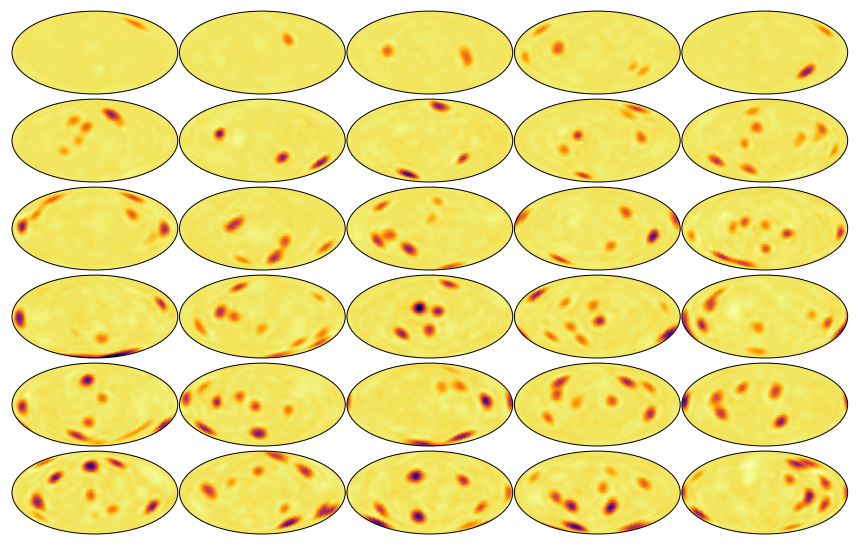

In [6]:
# Maps go down through draw_map, so PROJ, UP and SURFACE_CMAP in _setup
# apply here. One colour scale over the thirty panels, so a darker spot is a
# deeper spot wherever it sits in the gallery.
fig, axes = plt.subplots(*GALLERY, figsize=(WIDE, 4.4),
                         subplot_kw=MAP_KW)
vmin, vmax = imgs[show].min(), imgs[show].max()
for ax, k in zip(axes.ravel(), show):
    draw_map(ax, imgs[k], vmin=vmin, vmax=vmax)

# the panels carry no labels, so the layout is pulled in tight around them
fig.get_layout_engine().set(w_pad=0.005, h_pad=0.005, wspace=0.01,
                            hspace=0.01)

## Saving and caption numbers

Writes the pdf and png, then prints the caption numbers: the
filling-factor quantiles shown and whether the decoded intensities
stay physical.

In [7]:
save_fig(fig, 'fig11_vae_latent_samps')
print(f'gallery of {N_SHOW} decodes, {GALLERY[0]} by {GALLERY[1]}, '
      f'ordered by filling factor')
print('displayed sff values: '
      + ', '.join(f'{sff[k]:.4f}' for k in show))
print(f'sff range over all {len(idx):,} draws: {sff.min():.4f} to '
      f'{sff.max():.4f}')
print(f'decoded minimum intensity: median {np.median(mins):.3f}, '
      f'1st percentile {np.percentile(mins, 1):.3f}, '
      f'{np.mean(mins < 0) * 100:.2f} per cent of draws dip below '
      f'zero')
print(f'decoded background level away from spots: median of per-draw '
      f'maxima {np.median(imgs.max(axis=(1, 2))):.4f}')

wrote notebooks/paper/figs/fig11_vae_latent_samps.pdf, notebooks/paper/figs/fig11_vae_latent_samps.png
gallery of 30 decodes, 6 by 5, ordered by filling factor
displayed sff values: 0.0047, 0.0057, 0.0163, 0.0166, 0.0169, 0.0267, 0.0298, 0.0303, 0.0309, 0.0388, 0.0443, 0.0451, 0.0463, 0.0476, 0.0504, 0.0515, 0.0550, 0.0557, 0.0571, 0.0604, 0.0607, 0.0617, 0.0618, 0.0643, 0.0656, 0.0752, 0.0804, 0.0808, 0.0815, 0.0858
sff range over all 5,000 draws: 0.0000 to 0.1074
decoded minimum intensity: median 0.545, 1st percentile 0.276, 0.00 per cent of draws dip below zero
decoded background level away from spots: median of per-draw maxima 1.0243
